# Blog Analysis Agent v1

A LangGraph agent for **non-technical analysis and opinion pieces**: media, culture, business, society. Example: *"Will Indian TV and OTT ever have their Ted Lasso moment?"*

It shares plumbing with the technical blog agent (routing, Tavily research, tagging, QA snapshots), but the writing pipeline is different:

| Technical agent | Analysis agent |
|---|---|
| Outline of 5-9 sections | A **thesis** plus 3-6 argument **beats** |
| Parallel section workers | **One writer** drafts the whole piece, so the argument and voice stay coherent |
| No review step | An **editor** (Opus) checks the argument, grounding and prose, then revises |

Flow: `router → (research) → planner → writer → editor → tagger`

Required environment variables:
- `ANTHROPIC_API_KEY`
- `TAVILY_API_KEY`

In [47]:
from __future__ import annotations

import json
import re
from datetime import date, datetime, timedelta
from pathlib import Path
from typing import TypedDict, List, Optional, Literal, Dict
from urllib.parse import urlparse

from pydantic import BaseModel, Field

from langgraph.graph import StateGraph, START, END

from langchain_anthropic import ChatAnthropic
from langchain_core.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv
from langchain_tavily import TavilySearch

load_dotenv()

True

## Utilities

In [48]:
def to_snake_case(text):
    words = re.findall(r'[a-zA-Z0-9]+', text)
    return '_'.join(word.lower() for word in words)


def _iso_to_date(s: Optional[str]) -> Optional[date]:
    if not s:
        return None
    try:
        return date.fromisoformat(s[:10])
    except Exception:
        return None


def _yaml_str(s: str) -> str:
    return '"' + s.replace("\\", "\\\\").replace('"', '\\"') + '"'


def _prose_word_count(md: str) -> int:
    """Word count without link URLs or the H1 title."""
    md = re.sub(r"^# .*$", "", md, count=1, flags=re.M)
    md = re.sub(r"\[([^\]]*)\]\([^)]*\)", r"\1", md)
    return len(re.findall(r"\b\w+\b", md))


BLOCKED_DOMAINS = {
    "wikipedia.org", "instagram.com", "facebook.com", "x.com", "twitter.com",
    "youtube.com", "reddit.com", "quora.com", "pinterest.com",
}

def _is_blocked(url: str) -> bool:
    host = urlparse(url).netloc.lower()
    return any(host == d or host.endswith("." + d) for d in BLOCKED_DOMAINS)


def _evidence_block(evidence: list, raw_sources: Optional[dict] = None) -> str:
    """Numbered evidence list. With raw_sources, also includes Tavily's original text for checking."""
    if not evidence:
        return "(no evidence gathered)"
    blocks = []
    for i, e in enumerate(evidence, 1):
        block = (f"[{i}] {e.title} | {e.url} | {e.published_at or 'date:unknown'}\n"
                 f"    Snippet: {e.snippet or '(none)'}")
        if raw_sources and raw_sources.get(e.url):
            block += f"\n    Source text: {raw_sources[e.url][:1500]}"
        blocks.append(block)
    return "\n".join(blocks)

## Data model

The plan is **argument-shaped**, not section-shaped:
- `thesis`: the one-sentence answer to the question, which the piece argues for
- `beats`: the steps of the argument, each tied to evidence where it makes factual claims
- `counterpoint`: the strongest objection the piece has to address honestly

`piece_kind` covers the non-technical formats this agent writes. List fields carry no length limits in the schema, because native structured outputs reject most array-length constraints; the ranges live in the prompts.

In [49]:
class Beat(BaseModel):
    id: int
    point: str = Field(..., description="The claim this part of the piece makes, in one sentence.")
    support: str = Field(..., description="How the point will be supported: examples, data, reasoning.")
    evidence_ids: List[int] = Field(
        default_factory=list,
        description="Numbers of evidence items (from the numbered list) this beat relies on. Empty if pure reasoning.",
    )


class AnalysisPlan(BaseModel):
    title: str = Field(..., description="Headline. Specific and honest, not clickbait.")
    thesis: str = Field(..., description="One sentence: the piece's answer to the question.")
    piece_kind: Literal["analysis", "opinion", "explainer", "trend_piece", "review"] = "analysis"
    audience: str
    tone: str = Field(..., description="e.g. sharp and conversational, measured, wry.")
    target_words: int = Field(..., description="Total word count for the piece.")
    beats: List[Beat] = Field(..., description="3-6 beats, in the order the piece will make them.")
    counterpoint: str = Field(..., description="The strongest objection to the thesis, stated fairly.")
    constraints: List[str] = Field(default_factory=list)


class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None
    snippet: Optional[str] = None


class EvidencePack(BaseModel):
    evidence: List[EvidenceItem] = Field(default_factory=list)


class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"]
    queries: List[str] = Field(default_factory=list)


class EditResult(BaseModel):
    issues: List[str] = Field(..., description="Problems found in the draft and what was done about each.")
    revised_title: Optional[str] = Field(None, description="A better headline only if the revision changed the piece's angle; otherwise null.")
    revised_markdown: str = Field(..., description="The full revised piece in Markdown, without the H1 title.")


class BlogTags(BaseModel):
    tags: List[str] = Field(..., description="5-8 specific tags, lowercase and hyphen-separated.")


class State(TypedDict):
    topic: str
    target_words: Optional[int]   # optional override from run(); planner picks otherwise

    # routing / research
    mode: str
    needs_research: bool
    queries: List[str]
    evidence: List[EvidenceItem]
    raw_sources: Dict[str, str]   # url -> Tavily's original text, for the editor's checks
    as_of: str
    recency_days: int

    # planning / writing
    plan: Optional[AnalysisPlan]
    draft: str
    editor_issues: List[str]
    editor_revision: str
    final: str

    # tagging / output
    tags: List[str]
    output_path: str
    run_id: str

## Models

- **Router / research extraction / tagger** → Haiku: cheap, structured steps.
- **Planner and writer** → Sonnet.
- **Editor** → Opus: this is where the extra quality pays off. It catches weak reasoning, unsupported claims and flat prose.

`temperature` isn't set, because these models reject it. Style is steered through the prompts.

In [50]:
router_llm   = ChatAnthropic(model="claude-haiku-5-5",  max_tokens=1024)
research_llm = ChatAnthropic(model="claude-haiku-5-5",  max_tokens=4096)
planner_llm  = ChatAnthropic(model="claude-sonnet-5-5", max_tokens=4096)
writer_llm   = ChatAnthropic(model="claude-sonnet-5-5", max_tokens=4096)
editor_llm   = ChatAnthropic(model="claude-opus-5-5",   max_tokens=8192)
tagger_llm   = ChatAnthropic(model="claude-haiku-5-5",  max_tokens=1024)

## ROUTER

In [51]:
ROUTER_SYS_PROMPT = """
You are a routing module for an analysis and opinion blog (media, culture, business, society).
Decide whether web research is needed BEFORE planning.

Modes:
- closed_book (needs_research=false):
    Purely conceptual or reflective pieces where no specific facts, examples or numbers are needed.
- hybrid (needs_research=true):
    The argument is the writer's, but it needs real, current examples, data and context to be credible.
    Most analysis pieces belong here.
- open_book (needs_research=true):
    The piece is about recent events: "this week", "latest", breaking developments, new releases.

If needs_research=true:
- Output 4-8 specific queries that would surface evidence for AND against the likely answer.
- Split queries across: (a) the craft or creative side (critics, creators, interviews), 
  (b) concrete examples (named shows, companies, people), and (c) data (ratings, subscribers,
  market reports) only where the argument needs numbers. Don't let market data crowd out
  the substance of the question.
- Keep queries in the topic's own context (e.g. Indian market, Indian platforms) where the topic is local.
- If the user asked for "this week" or "latest", reflect that constraint in the queries.
"""


def router_node(state: State) -> dict:
    decider = router_llm.with_structured_output(RouterDecision, method="json_schema")
    decision = decider.invoke(
        [
            SystemMessage(content=ROUTER_SYS_PROMPT),
            HumanMessage(content=f"Topic: {state['topic']}\nAs-of date: {state['as_of']}"),
        ]
    )

    if decision.mode == "open_book":
        recency_days = 7
    elif decision.mode == "hybrid":
        recency_days = 365
    else:
        recency_days = 3650

    return {
        "needs_research": decision.needs_research,
        "mode": decision.mode,
        "queries": decision.queries,
        "recency_days": recency_days,
    }


def route_next(state: State) -> str:
    return "research" if state["needs_research"] else "planner"

## RESEARCH (Tavily)

In [52]:
TIME_RANGE = {"open_book": "week", "hybrid": None, "closed_book": None}

def _tavily_search(query: str, max_results: int = 5, topic: str = "general", time_range: Optional[str] = None) -> List[dict]:
    kwargs = {"max_results": max_results, "topic": topic}
    if time_range:
        kwargs["time_range"] = time_range
    tool = TavilySearch(**kwargs)
    response = tool.invoke({"query": query})
    if not isinstance(response, dict):
        raise TypeError(f"Expected a Tavily response dict, got {type(response).__name__}")
    if "error" in response:
        raise RuntimeError(f"Tavily search failed: {response['error']}")

    normalized: List[dict] = []
    for r in response.get("results", []) or []:
        if not isinstance(r, dict):
            continue
        normalized.append(
            {
                "title": r.get("title") or "",
                "url": r.get("url") or "",
                "snippet": r.get("content") or r.get("snippet") or "",
                "published_at": r.get("published_date") or r.get("published_at"),
            }
        )
    return normalized


RESEARCH_SYSTEM = """You are a research assistant for an analysis and opinion blog.

Given raw web search results, produce a deduplicated list of EvidenceItem objects.

Rules:
- Only include items with a non-empty url that are specifically about the topic.
- Drop homepages, listing/category pages, generic encyclopedia pages, SEO filler and unrelated news.
- Prefer reporting, data and informed commentary: established publications, trade press, industry reports,
  interviews, critics. Keep a mix of sources that support and challenge the likely answer.
- Snippets: 1-3 sentences that keep the concrete facts (names, numbers, dates, quotes) the source actually states.
  Never add anything that is not in the raw result.
- If a published date is explicitly present, keep it as YYYY-MM-DD. Otherwise published_at=null. Do NOT guess.
- Deduplicate by URL.
"""


def research_node(state: State) -> dict:
    queries = (state.get("queries") or [])[:8]
    mode = state.get("mode")
    topic = "news" if mode == "open_book" else "general"   # "news" returns published dates

    raw_results: List[dict] = []
    for q in queries:
        raw_results.extend(_tavily_search(q, 5, topic, TIME_RANGE.get(mode)))

    # Enforce source rules in code, before the LLM sees anything
    raw_results = [r for r in raw_results if r["url"] and not _is_blocked(r["url"])]
    if not raw_results:
        return {"evidence": [], "raw_sources": {}}
    raw_by_url = {r["url"]: r["snippet"] for r in raw_results}

    extractor = research_llm.with_structured_output(EvidencePack, method="json_schema")
    pack = extractor.invoke(
        [
            SystemMessage(content=RESEARCH_SYSTEM),
            HumanMessage(
                content=(
                    f"Topic: {state['topic']}\n"
                    f"As-of date: {state['as_of']}\n\n"
                    f"Raw results:\n{raw_results}"
                )
            ),
        ]
    )

    dedup = {e.url: e for e in pack.evidence if e.url and not _is_blocked(e.url)}
    evidence = list(dedup.values())

    # Drop items known to be too old; keep undated ones (time_range already filtered at search)
    if mode == "open_book":
        cutoff = date.fromisoformat(state["as_of"]) - timedelta(days=int(state["recency_days"]))
        evidence = [e for e in evidence if (d := _iso_to_date(e.published_at)) is None or d >= cutoff]

    return {
        "evidence": evidence,
        "raw_sources": {e.url: raw_by_url.get(e.url, "") for e in evidence},
    }

## PLANNER (thesis + beats)

In [53]:
PLANNER_SYSTEM = """You are the commissioning editor of a smart, independent publication on media, culture,
business and society. Plan ONE analysis or opinion piece.

The plan must be argument-shaped:
- thesis: a clear, arguable one-sentence answer to the question. Not a fence-sit ("it depends").
  A qualified answer is fine ("Yes, but not from the platforms everyone expects").
- beats: 3-6 steps that build the argument in order. Each beat makes ONE point and says how it will be supported.
  Where a beat makes factual claims, list the evidence numbers it relies on.
- counterpoint: the strongest objection to the thesis, stated fairly. The piece will address it.

Length:
- "short": 450-650 words.
- Unspecified: 700-1000 words. Longer only if the request asks for it.
- If a target word count is given, use it.

Grounding:
- Only reference evidence numbers that exist in the provided list.
- Do not plan beats around specific facts (ratings, numbers, events) that the evidence does not contain.
  If evidence is thin, lean the beats on reasoning and well-known context, and keep claims modest.

Avoid:
- Listicle structure, "5 reasons why" framing, or a beat per example.
- A beat that only summarizes the topic. Context belongs inside the first beat, briefly.
"""


def planner_node(state: State) -> dict:
    planner = planner_llm.with_structured_output(AnalysisPlan, method="json_schema")
    target = state.get("target_words")

    plan = planner.invoke(
        [
            SystemMessage(content=PLANNER_SYSTEM),
            HumanMessage(
                content=(
                    f"Request: {state['topic']}\n"
                    f"Mode: {state['mode']}\n"
                    f"As-of: {state['as_of']}\n"
                    f"Target words: {target or 'decide from the request'}\n\n"
                    f"Evidence:\n{_evidence_block(state.get('evidence', []))}"
                )
            ),
        ]
    )

    if target:
        plan.target_words = target

    # Drop references to evidence numbers that don't exist
    n = len(state.get("evidence", []))
    for b in plan.beats:
        b.evidence_ids = [i for i in b.evidence_ids if 1 <= i <= n]

    return {"plan": plan}

## WRITER (one pass, whole piece)

One writer drafts the whole piece, so the argument builds and the voice stays consistent.

In [54]:
WRITER_SYSTEM = """You write sharp, readable analysis for an independent publication on media, culture,
business and society. Write the piece described by the plan, in Markdown.

Structure:
- Do NOT include the H1 title; it is added later.
- Open with a concrete hook (a scene, a fact, a contrast), then state the thesis within the first two paragraphs.
- Follow the beats in order. Use at most 2-3 short subheadings (##), or none if the piece flows better without.
- Address the counterpoint honestly before the ending, then close on the thesis with something sharper than a summary.
- Stay within ±10% of the target word count.

Grounding:
- Specific facts (numbers, ratings, dates, quotes, deals, who-said-what) must come from the evidence snippets.
- Cite inline, journalism style: link the phrase the fact appears in, e.g. "...[topped the platform's charts](URL)...".
  Use only URLs from the evidence list, and only for claims that URL's snippet actually supports.
- If you need a fact the evidence doesn't contain, make the point without the specific figure, or leave it out.
- Analysis, interpretation and opinion are yours to make; they don't need citations.
- Evidence marked date:unknown may be old. Don't present its quotes or figures as current
  ("still", "now", "today") unless the snippet says when.

Style:
- Concrete over abstract: name shows, people, platforms, moments.
- Vary sentence length. Short paragraphs.
- No clichés: "in today's fast-paced world", "game-changer", "it remains to be seen", "only time will tell",
  "in conclusion", "a testament to", "delve".
- No hedging every sentence. Commit to the thesis.
"""


def _plan_text(plan: AnalysisPlan, evidence: list, raw_sources: Optional[dict] = None) -> str:
    beats = "\n".join(
        f"{b.id}. {b.point}\n   Support: {b.support}\n   Evidence: {', '.join(f'[{i}]' for i in b.evidence_ids) or 'reasoning only'}"
        for b in plan.beats
    )
    return (
        f"Title: {plan.title}\n"
        f"Thesis: {plan.thesis}\n"
        f"Kind: {plan.piece_kind}\n"
        f"Audience: {plan.audience}\n"
        f"Tone: {plan.tone}\n"
        f"Target words: {plan.target_words}\n"
        f"Constraints: {plan.constraints}\n\n"
        f"Beats:\n{beats}\n\n"
        f"Counterpoint to address: {plan.counterpoint}\n\n"
        f"Evidence:\n{_evidence_block(evidence, raw_sources)}"
    )


def writer_node(state: State) -> dict:
    plan = state["plan"]
    if plan is None:
        raise ValueError("Writer called without a plan.")

    draft = writer_llm.invoke(
        [
            SystemMessage(content=WRITER_SYSTEM),
            HumanMessage(content=f"Original request: {state['topic']}\n\n{_plan_text(plan, state.get('evidence', []))}"),
        ]
    ).text.strip()

    return {"draft": draft}

## EDITOR (critique + revise)

The editor reviews the draft against the plan and evidence, lists what it fixed, and returns the full revised piece. The `issues` list is saved in the QA snapshots, so you can see what the editor changed and why.

In [55]:
EDITOR_SYSTEM = """You are a demanding but fair senior editor. Review the draft against the plan and evidence,
then return the revised piece.

Check, in order:
1. Argument: is the thesis stated early and actually argued? Does each section earn its place?
   Is the counterpoint addressed honestly rather than waved away?
2. Grounding: every specific fact (number, date, rating, quote, deal) must be supported by the
   Source text of the evidence item it links to (use the Snippet only if there is no Source text).
   Remove or soften any claim that isn't. Never add new facts or new URLs.
3. Reasoning: does each inference actually follow from the fact it cites? Flag statistics used to
   prove more than they show (e.g. a genre share that includes the very category being argued for).
4. Prose: cut clichés, filler, repetition and throat-clearing. Tighten flabby sentences. Keep the writer's voice;
   don't flatten it into corporate prose.
5. Length: within ±10% of the target word count.

Output:
- issues: a short list of what you found and what you did about each (e.g. "Removed unsupported subscriber
  figure in para 4"). Empty list only if the draft genuinely needed nothing.
- revised_markdown: the complete revised piece, without the H1 title.
- revised_title: a better headline only if your revision changed the piece's angle; otherwise null.
"""


def editor_node(state: State) -> dict:
    plan = state["plan"]
    editor = editor_llm.with_structured_output(EditResult, method="json_schema")
    result = editor.invoke(
        [
            SystemMessage(content=EDITOR_SYSTEM),
            HumanMessage(
                content=(
                    f"{_plan_text(plan, state.get('evidence', []), state.get('raw_sources'))}\n\n"
                    f"---\nDRAFT:\n\n{state['draft']}"
                )
            ),
        ]
    )

    body = result.revised_markdown.strip()
    editor_revision = body
    issues = list(result.issues)

    # Verify length in code; one corrective pass if the editor missed
    words = _prose_word_count(body)
    lo, hi = int(plan.target_words * 0.9), int(plan.target_words * 1.1)
    if not lo <= words <= hi:
        body = editor_llm.invoke(
            [
                SystemMessage(content="Adjust this piece's length. Keep the argument, voice, facts and links "
                                      "unchanged. Return only the Markdown body, no title."),
                HumanMessage(content=f"Current: {words} words (excluding links). "
                                     f"Target: {plan.target_words} (±10%).\n\n{body}"),
            ]
        ).text.strip()
        issues.append(f"Length pass: {words} → {_prose_word_count(body)} words.")

    if result.revised_title:
        plan = plan.model_copy(update={"title": result.revised_title})

    return {
        "final": f"# {plan.title}\n\n{body}\n",
        "editor_issues": issues, 
        "plan": plan,
        "editor_revision": editor_revision
    }

## TAGGER

Same approach as the technical agent: the model proposes tags, code normalizes them, and the post is saved with YAML front matter. The thesis goes in as `description`, which most CMSs and static-site generators use for previews and SEO.

In [56]:
MIN_TAGS, MAX_TAGS = 5, 8

TAGGER_SYSTEM = f"""You assign tags to a finished analysis or opinion piece.

- {MIN_TAGS}-{MAX_TAGS} tags, lowercase, hyphen-separated (e.g. "indian-ott", "television-comedy", "streaming-economics").
- Always include the piece's main subject as a tag.
- Tags must reflect what the piece actually discusses in depth, not things mentioned in passing.
- Prefer specific subjects, places, industries and named works over generic words like "opinion", "analysis",
  "entertainment", "culture", "blog".
- No near-duplicates.
"""


def _normalize_tag(t: str) -> str:
    return re.sub(r"[^a-z0-9]+", "-", t.lower()).strip("-")


def tagger_node(state: State) -> dict:
    plan = state["plan"]
    tagger = tagger_llm.with_structured_output(BlogTags, method="json_schema")
    result = tagger.invoke(
        [
            SystemMessage(content=TAGGER_SYSTEM),
            HumanMessage(
                content=(
                    f"Title: {plan.title}\n"
                    f"Thesis: {plan.thesis}\n"
                    f"Request: {state['topic']}\n\n"
                    f"Piece:\n{state['final'][:12000]}"
                )
            ),
        ]
    )

    generic = {"opinion", "analysis", "blog", "culture", "entertainment", "news", "essay"}
    tags: List[str] = []
    for t in result.tags:
        n = _normalize_tag(t)
        if n and n not in generic and n not in tags:
            tags.append(n)
    tags = tags[:MAX_TAGS]

    return {"tags": tags}

## SAVE BLOG TO FILE

In [57]:
def save_node(state: State) -> dict:
    plan = state["plan"]
    front_matter = (
        "---\n"
        f"title: {_yaml_str(plan.title)}\n"
        f"date: {state['as_of']}\n"
        f"piece_kind: {plan.piece_kind}\n"
        f"description: {_yaml_str(plan.thesis)}\n"
        "tags: [" + ", ".join(state["tags"]) + "]\n"
        "---\n\n"
    )
    output_path = Path("blog_posts") / f"{state.get('run_id') or to_snake_case(plan.title)}.md"
    output_path.parent.mkdir(parents=True, exist_ok=True)   # the old code failed if the folder was missing
    output_path.write_text(front_matter + state["final"], encoding="utf-8")
    return {"output_path": str(output_path)}

## GRAPH

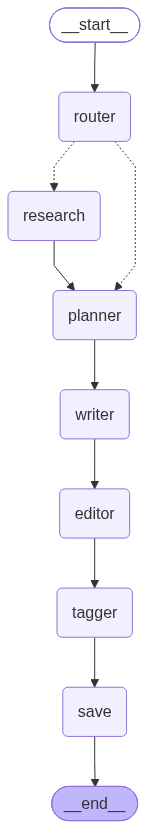

In [58]:
g = StateGraph(State)
g.add_node("router", router_node)
g.add_node("research", research_node)
g.add_node("planner", planner_node)
g.add_node("writer", writer_node)
g.add_node("editor", editor_node)
g.add_node("tagger", tagger_node)
g.add_node("save", save_node)

g.add_edge(START, "router")
g.add_conditional_edges("router", route_next, {"research": "research", "planner": "planner"})
g.add_edge("research", "planner")
g.add_edge("planner", "writer")
g.add_edge("writer", "editor")
g.add_edge("editor", "tagger")
g.add_edge("tagger", "save")
g.add_edge("save", END)

app = g.compile()

app

## QA SNAPSHOTS

Same layout as the technical agent. Each run gets `runs/<YYYYMMDD-HHMMSS>_<topic_slug>/` containing `00_input.json`, one `NN_<node>.json` per node (with `update` and `state_after`) and `final_state.json`.

For this agent, two snapshots are especially useful in QA:
- `NN_writer.json`: the first draft, before editing
- `NN_editor.json`: `editor_issues` lists what the editor changed and why

In [59]:
import difflib

def _sentences(md: str) -> List[str]:
    """One sentence per line, so diffs show the sentence that changed, not the whole paragraph."""
    lines = []
    for para in md.strip().split("\n"):
        if not para.strip():
            lines.append("")
            continue
        lines.extend(s for s in re.split(r"(?<=[.!?])\s+", para.strip()) if s)
    return lines


def _write_diff(path: Path, before: str, after: str, before_name: str, after_name: str) -> None:
    diff = difflib.unified_diff(
        _sentences(before), _sentences(after),
        fromfile=before_name, tofile=after_name, lineterm="",
    )
    text = "\n".join(diff)
    path.write_text(text + "\n" if text else "(no changes)\n", encoding="utf-8")



def _to_jsonable(obj):
    if isinstance(obj, BaseModel):
        return obj.model_dump(mode="json")
    if isinstance(obj, dict):
        return {str(k): _to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [_to_jsonable(v) for v in obj]
    if obj is None or isinstance(obj, (str, int, float, bool)):
        return obj
    return str(obj)


def _save_json(path: Path, data) -> None:
    path.write_text(json.dumps(_to_jsonable(data), indent=2, ensure_ascii=False), encoding="utf-8")

## RUN

In [60]:
def run(topic: str, target_words: Optional[int] = None, as_of: Optional[str] = None, qa_dir: str = "runs"):
    if as_of is None:
        as_of = date.today().isoformat()

    slug = to_snake_case(topic)
    if len(slug) > 50:
        slug = slug[:50].rsplit("_", 1)[0]   # cut at the last full word
    slug = slug.strip("_")

    run_id = f"{datetime.now():%Y%m%d-%H%M%S}_{slug}"
    run_dir = Path(qa_dir) / run_id
    run_dir.mkdir(parents=True, exist_ok=True)

    initial_state = {
        "topic": topic,
        "target_words": target_words,
        "mode": "",
        "needs_research": False,
        "queries": [],
        "evidence": [],
        "raw_sources": {},
        "as_of": as_of,
        "recency_days": 365,   # router may overwrite
        "plan": None,
        "draft": "",
        "editor_issues": [],
        "editor_revision": "",
        "final": "",
        "tags": [],
        "output_path": "",
        "run_id": run_id,
    }

    step = 0
    pending: List[tuple[str, dict]] = []
    out = None
    for mode, chunk in app.stream(initial_state, stream_mode=["updates", "values"]):
        if mode == "updates":
            for node, update in chunk.items():
                pending.append((node, update or {}))
            continue

        out = chunk
        if not pending:
            _save_json(run_dir / f"{step:02d}_input.json", {"step": step, "node": "input", "state": chunk})
        for node, update in pending:
            _save_json(
                run_dir / f"{step:02d}_{node}.json",
                {"step": step, "node": node, "update": update, "state_after": chunk},
            )
        pending = []
        step += 1

    _save_json(run_dir / "final_state.json", out)

    # Versions side by side, for assessing the editor
    final_body = re.sub(r"^# .*\n\n", "", out["final"], count=1)
    versions = {
        "v1_writer_draft.md": out["draft"],
        "v2_editor_revision.md": out["editor_revision"],
        "v3_final.md": final_body,
    }
    for name, text in versions.items():
        (run_dir / name).write_text(text, encoding="utf-8")

    _write_diff(run_dir / "diff_1_writer_to_editor.diff",
                out["draft"], out["editor_revision"], "writer_draft", "editor_revision")
    _write_diff(run_dir / "diff_2_editor_to_final.diff",
                out["editor_revision"], final_body, "editor_revision", "final")

    plan: AnalysisPlan = out["plan"]
    print("\n" + "=" * 100)
    print("TOPIC:", topic)
    print("MODE:", out.get("mode"), "| EVIDENCE:", len(out.get("evidence", [])))
    print("TITLE:", plan.title)
    print("THESIS:", plan.thesis)
    print("BEATS:", len(plan.beats), "| TARGET_WORDS:", plan.target_words,
          "| FINAL_WORDS:", _prose_word_count(out.get("final", "")))
    print("EDITOR_ISSUES:", len(out.get("editor_issues", [])))
    for issue in out.get("editor_issues", [])[:8]:
        print("  -", issue)
    print("TAGS:", out.get("tags"))
    print("SAVED_TO:", out.get("output_path"))
    print("QA_SNAPSHOTS:", run_dir)
    print("=" * 100 + "\n")

    return out

In [62]:
out = run("What are the lessons that Indian TV can take from Hollywood in creating female-centric series?")


TOPIC: What are the lessons that Indian TV can take from Hollywood in creating female-centric series?
MODE: hybrid | EVIDENCE: 7
TITLE: Indian TV Doesn't Need Hollywood's Heroines. It Needs Hollywood's Writers' Rooms
THESIS: The most useful lesson Indian TV can take from Hollywood is structural rather than aesthetic: women-led series get better when women hold creative and ownership power and when characters are allowed to be flawed, specific and uncomfortable, not when Indian shows copy Western templates of the 'strong female lead'.
BEATS: 5 | TARGET_WORDS: 850 | FINAL_WORDS: 892
EDITOR_ISSUES: 10
  - Factual error in the Rotten Tomatoes paragraph: the draft credited Jenji Kohan with Grace and Frankie. The source text attributes that show to Kauffman, the Friends co-creator. Fixed the attribution.
  - The draft said that even the better Netflix series fall short of being free of gender bias. That claim appears only in the snippet, not the source text, so I removed it.
  - 'Hollywood'